# Entrega 3 — Primer experimento con una red feedforward

**Objetivo:** entrenar una red completamente conectada real como baseline exploratorio
para los doce hallazgos de RSNA Knee Abnormality Detection. No usamos convoluciones ni
pesos preentrenados. No se busca un modelo clínico ni el resultado final del proyecto.

En VS Code selecciona el kernel de `.venv` y ejecuta **Run All**. La preparación se
realiza una sola vez desde la raíz: `uv run python preparar_ff.py`.
Este notebook usa exclusivamente imágenes y etiquetas explícitas; los reportes
no son entradas del modelo. Las imágenes no se redistribuyen con el notebook.

In [1]:
from pathlib import Path
import json
import random
import time
import platform
import hashlib
import importlib.metadata as metadata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import roc_auc_score, f1_score, precision_score, recall_score
from IPython.display import display

get_ipython().run_line_magic('matplotlib', 'inline')

ROOT = Path.cwd()
if not (ROOT / 'pyproject.toml').exists():
    ROOT = ROOT.parent
assert (ROOT / 'pyproject.toml').exists(), 'Abre el notebook desde la carpeta redes.'
OUT = ROOT / 'resultados_ff'
OUT.mkdir(exist_ok=True)
SEED = 42
torch.set_num_threads(2)
DEVICE = torch.device('cpu')  # Baseline pequeño y reproducible sin requerir GPU.

def seed_all(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

seed_all()
versions = {name: metadata.version(name) for name in
            ['torch', 'numpy', 'pandas', 'matplotlib', 'scikit-learn', 'pydicom']}
versions.update(python=platform.python_version(), device=str(DEVICE), seed=SEED)
print(versions)

{'torch': '2.14.1', 'numpy': '2.5.4', 'pandas': '3.0.6', 'matplotlib': '3.11.2', 'scikit-learn': '1.9.1', 'pydicom': '3.0.2', 'python': '3.12.14', 'device': 'cpu', 'seed': 42}


## 1. Datos reales y simplificación del experimento

De 4,407 estudios, solo **58 tienen las doce etiquetas explícitas**. Para este avance
usamos esos 58 en entrenamiento y validación; dejan de constituir una prueba final
independiente para futuros modelos.

Se selecciona una serie sagital por estudio, priorizando sensibilidad al líquido y
supresión de grasa; los empates se resuelven por UID. Se eligen cinco archivos
uniformemente del listado ordenado por UID. **Los UID no indican posición anatómica**:
este muestreo barato no garantiza cobertura uniforme de la rodilla. Después de
descargarlos, los cinco cortes sí se ordenan por geometría DICOM.

Cada corte se normaliza individualmente con percentiles 1 y 99 de píxeles válidos,
se corrige MONOCHROME1 si corresponde y se reduce a **32 × 32**, conservando proporción
con relleno. Esta reducción pierde detalle; es una simplificación explícita para el
baseline. Cinco cortes aplanados producen **5,120 entradas por estudio**. No tratamos
cada corte como un paciente independiente.

In [2]:
path = ROOT / 'datos_ff/estudios_ff.npz'
if not path.exists():
    raise FileNotFoundError('Primero ejecuta: uv run python preparar_ff.py')
with np.load(path, allow_pickle=False) as data:
    images, y = data['X'].copy(), data['y'].copy()
    studies, groups, labels = data['studies'].copy(), data['groups'].copy(), data['labels'].tolist()
assert images.shape == (58, 5, 32, 32)
assert y.shape == (58, 12) and np.isin(y, [0, 1]).all()
assert np.isfinite(images).all() and len(set(studies)) == len(studies)
manifest = json.loads((ROOT / 'datos_ff/manifest.json').read_text())
print(f'{len(y)} estudios; {images.shape[1]} cortes por estudio; {len(labels)} hallazgos.')
print('Planos utilizados:', sorted(set(item['plane'] for item in manifest)))
print('Estudios con identificador de paciente:', sum(item['patient_identifiable'] for item in manifest))
display(pd.DataFrame({'hallazgo': labels, 'positivos': y.sum(axis=0).astype(int),
                      'negativos': (1-y).sum(axis=0).astype(int)}))

58 estudios; 5 cortes por estudio; 12 hallazgos.
Planos utilizados: ['Sagittal']
Estudios con identificador de paciente: 58


,hallazgo,positivos,negativos
0,ACL,24,34
1,MCL,9,49
2,Medial Meniscus,26,32
3,Lateral Meniscus,23,35
4,Medial OA,15,43
5,Lateral OA,11,47
6,PF OA,21,37
7,Effusion,35,23
8,Synovitis,27,31
9,Baker's,12,46


## 2. Separación fija y normalización

Separamos aproximadamente 80%/20% con semilla 42, agrupando por identificador de
paciente cuando existe y también por reportes idénticos. Solo se utilizan los reportes
para prevenir duplicados entre particiones, nunca como entrada. No hay conjunto de test.
La validación se usa para comparar configuraciones y elegir época, por lo que sus
métricas son exploratorias y pueden resultar optimistas.

La media y desviación globales de los píxeles se calculan **solo en entrenamiento**.
Mantenemos exactamente los mismos estudios, imágenes, particiones, lotes y umbral en
los tres experimentos. No buscamos una partición en función de sus resultados.

In [3]:
# Unión de grupos de paciente y reportes idénticos, sin imprimir textos clínicos.
train_csv = pd.read_csv(ROOT / 'muestra_rsna/datos/train.csv').set_index('StudyInstanceUID')
reports = train_csv.loc[studies, 'Report'].fillna('').tolist()
parent = list(range(len(studies)))
def find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]
        i = parent[i]
    return i
seen_patient, seen_report = {}, {}
for i, (group, report) in enumerate(zip(groups, reports)):
    keys = [(seen_patient, str(group))]
    normalized = ' '.join(str(report).lower().split())
    if normalized:
        keys.append((seen_report, hashlib.sha256(normalized.encode()).hexdigest()))
    for seen, key in keys:
        if key in seen:
            parent[find(i)] = find(seen[key])
        else:
            seen[key] = i
split_groups = np.array([find(i) for i in range(len(studies))])
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, val_idx = next(splitter.split(images, y, groups=split_groups))
assert not set(split_groups[train_idx]) & set(split_groups[val_idx])
X = images.reshape(len(images), -1)
mean, std = float(X[train_idx].mean()), float(X[train_idx].std())
assert std > 0
X = (X-mean)/std
X_train, X_val = torch.from_numpy(X[train_idx]), torch.from_numpy(X[val_idx])
y_train, y_val = torch.from_numpy(y[train_idx]), torch.from_numpy(y[val_idx])
split = {'seed': SEED, 'train_studies': studies[train_idx].tolist(),
         'validation_studies': studies[val_idx].tolist(), 'mean_train': mean, 'std_train': std,
         'grouping': 'patient_identifier_and_identical_reports'}
(ROOT / 'datos_ff/split.json').write_text(json.dumps(split, indent=2))
print(f'Entrenamiento: {len(train_idx)} estudios; validación: {len(val_idx)} estudios.')
display(pd.DataFrame({'hallazgo': labels, 'positivos_train': y[train_idx].sum(0).astype(int),
                      'positivos_val': y[val_idx].sum(0).astype(int)}))

Entrenamiento: 46 estudios; validación: 12 estudios.


,hallazgo,positivos_train,positivos_val
0,ACL,21,3
1,MCL,6,3
2,Medial Meniscus,21,5
3,Lateral Meniscus,19,4
4,Medial OA,11,4
5,Lateral OA,11,0
6,PF OA,17,4
7,Effusion,27,8
8,Synovitis,23,4
9,Baker's,10,2


### Inspección de la entrada

Estos son los cinco cortes del primer estudio de entrenamiento tal como los verá
la red antes de aplanarlos. La visualización permite reconocer la pérdida de detalle
por la resolución reducida; no se interpreta ninguna lesión a partir de ella.

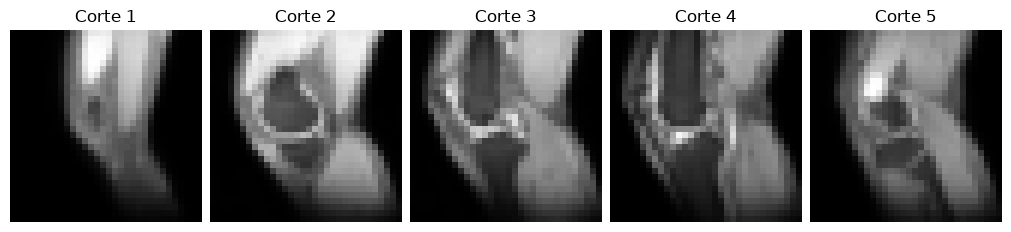

In [4]:
fig, axes = plt.subplots(1, 5, figsize=(10, 2.5), constrained_layout=True)
for i, ax in enumerate(axes):
    ax.imshow(images[train_idx[0], i], cmap='gray', vmin=0, vmax=1)
    ax.set_title(f'Corte {i+1}')
    ax.axis('off')
fig.savefig(OUT / 'entrada_ejemplo.png', dpi=150)
plt.show()

## 3. Red feedforward, activaciones y función de pérdida

La entrada aplanada pasa por una o dos capas densas con ReLU y una salida de doce
logits. Cada hallazgo es independiente: aplicamos sigmoide para obtener probabilidades,
**sin softmax**. `BCEWithLogitsLoss` combina sigmoide y entropía cruzada de forma estable,
por lo que recibe logits directamente. Adam actualiza los pesos con los gradientes
calculados por `loss.backward()`. No usamos convolución ni extracción preentrenada.

Reportamos pérdida, exactitud binaria por hallazgo (no exactitud clínica), F1 micro,
sensibilidad y precisión micro y ROC-AUC macro. La exactitud puede favorecer etiquetas
negativas frecuentes. AUC se calcula solo para hallazgos con positivos y negativos en
la partición; se informa cuántos son calculables. El umbral es fijo en 0.5.

In [5]:
class FeedForward(nn.Module):
    def __init__(self, input_dim, hidden, outputs):
        super().__init__()
        layers = []
        previous = input_dim
        for width in hidden:
            layers.extend([nn.Linear(previous, width), nn.ReLU()])
            previous = width
        layers.append(nn.Linear(previous, outputs))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)

criterion = nn.BCEWithLogitsLoss()

def metrics(target, probs):
    pred = (probs >= 0.5).astype(int)
    valid = [k for k in range(target.shape[1]) if len(np.unique(target[:, k])) == 2]
    auc = [roc_auc_score(target[:, k], probs[:, k]) for k in valid]
    return {'binary_accuracy': float((pred == target).mean()),
            'f1_micro': float(f1_score(target, pred, average='micro', zero_division=0)),
            'precision_micro': float(precision_score(target, pred, average='micro', zero_division=0)),
            'recall_micro': float(recall_score(target, pred, average='micro', zero_division=0)),
            'auc_macro': float(np.mean(auc)) if auc else None, 'auc_classes': len(valid)}

def evaluate(model, inputs, targets):
    model.eval()
    with torch.no_grad():
        logits = model(inputs.to(DEVICE))
        loss = float(criterion(logits, targets.to(DEVICE)))
        probs = torch.sigmoid(logits).cpu().numpy()
    return loss, metrics(targets.numpy(), probs), probs

## 4. Tres combinaciones de hiperparámetros

Todos los modelos entrenan 40 épocas con lotes de ocho estudios. A y B solo difieren
en tasa de aprendizaje; A y C difieren en anchura y profundidad. No variamos todos los
factores a la vez. Cada ejecución empieza con pesos nuevos y semilla 42. Registramos
todas las épocas y elegimos el checkpoint de menor pérdida de validación, sin detener
anticipadamente, para observar las curvas completas.

In [6]:
configs = [
    {'experiment': 'A', 'hidden': [64], 'lr': 1e-3, 'epochs': 40, 'batch_size': 8},
    {'experiment': 'B', 'hidden': [64], 'lr': 1e-4, 'epochs': 40, 'batch_size': 8},
    {'experiment': 'C', 'hidden': [128, 64], 'lr': 1e-3, 'epochs': 40, 'batch_size': 8},
]
display(pd.DataFrame(configs))

def train_experiment(config):
    seed_all()
    model = FeedForward(X.shape[1], config['hidden'], len(labels)).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=config['lr'])
    generator = torch.Generator().manual_seed(SEED)
    loader = DataLoader(TensorDataset(X_train, y_train), batch_size=config['batch_size'],
                        shuffle=True, generator=generator)
    history, best_loss, best_state, best_epoch = [], float('inf'), None, None
    started = time.perf_counter()
    for epoch in range(1, config['epochs']+1):
        model.train()
        for batch_x, batch_y in loader:
            optimizer.zero_grad()
            logits = model(batch_x.to(DEVICE))
            loss = criterion(logits, batch_y.to(DEVICE))
            loss.backward()
            optimizer.step()
        # Ambas pérdidas se miden al final de la época con los mismos pesos.
        train_loss, train_metrics, _ = evaluate(model, X_train, y_train)
        val_loss, val_metrics, _ = evaluate(model, X_val, y_val)
        assert np.isfinite(train_loss) and np.isfinite(val_loss), 'Pérdida no finita.'
        history.append({'epoch': epoch, 'train_loss': train_loss, 'val_loss': val_loss,
                        'train_accuracy': train_metrics['binary_accuracy'],
                        'val_accuracy': val_metrics['binary_accuracy']})
        if val_loss < best_loss:
            best_loss, best_epoch = val_loss, epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    elapsed = time.perf_counter()-started
    model.load_state_dict(best_state)
    train_loss, train_metrics, _ = evaluate(model, X_train, y_train)
    val_loss, val_metrics, probs = evaluate(model, X_val, y_val)
    summary = dict(config, parameters=sum(p.numel() for p in model.parameters()),
                   best_epoch=best_epoch, train_loss=train_loss, val_loss=val_loss,
                   seconds=elapsed, **val_metrics)
    name = config['experiment']
    frame = pd.DataFrame(history)
    frame.to_csv(OUT / f'history_{name}.csv', index=False)
    torch.save({'state_dict': best_state, 'config': config, 'input_dim': X.shape[1],
                'labels': labels, 'normalization': {'mean': mean, 'std': std},
                'best_epoch': best_epoch}, OUT / f'model_{name}.pt')
    # Predicciones asociadas a filas del split privado, sin identificadores en el CSV.
    pd.DataFrame(probs, columns=labels).to_csv(OUT / f'validation_predictions_{name}.csv', index=False)
    print(f'{name}: mejor época {best_epoch}; pérdida val={val_loss:.4f}; '
          f'F1 micro={val_metrics["f1_micro"]:.4f}; {elapsed:.2f} s')
    return summary, frame, probs

summaries, histories, probabilities = [], {}, {}
for config in configs:
    summary, history, probs = train_experiment(config)
    summaries.append(summary)
    histories[config['experiment']] = history
    probabilities[config['experiment']] = probs
results = pd.DataFrame(summaries)
results.to_csv(OUT / 'experiments.csv', index=False)
(OUT / 'versions.json').write_text(json.dumps(versions, indent=2))
display(results)

,experiment,hidden,lr,epochs,batch_size
0,A,[64],0.0010,40,8
1,B,[64],0.0001,40,8
2,C,"[128, 64]",0.0010,40,8


A: mejor época 1; pérdida val=0.6634; F1 micro=0.3810; 2.06 s


B: mejor época 3; pérdida val=0.6104; F1 micro=0.3478; 2.08 s


C: mejor época 2; pérdida val=0.6409; F1 micro=0.2609; 2.35 s


,experiment,hidden,lr,epochs,batch_size,parameters,best_epoch,train_loss,val_loss,seconds,binary_accuracy,f1_micro,precision_micro,recall_micro,auc_macro,auc_classes
0,A,[64],0.0010,40,8,328524,1,0.552966,0.663375,2.057822,0.638889,0.380952,0.355556,0.410256,0.461303,10
1,B,[64],0.0001,40,8,328524,3,0.540795,0.610398,2.083791,0.687500,0.347826,0.400000,0.307692,0.462698,10
2,C,"[128, 64]",0.0010,40,8,664524,2,0.522260,0.640928,2.346051,0.645833,0.260870,0.300000,0.230769,0.416905,10


## 5. Curvas de aprendizaje reales

La línea vertical marca el checkpoint elegido. Una pérdida de entrenamiento que baja
mientras la de validación sube indica sobreajuste. Las oscilaciones son esperables con
pocos estudios. La exactitud binaria es complementaria; no sustituye a la pérdida ni
a las métricas que consideran positivos.

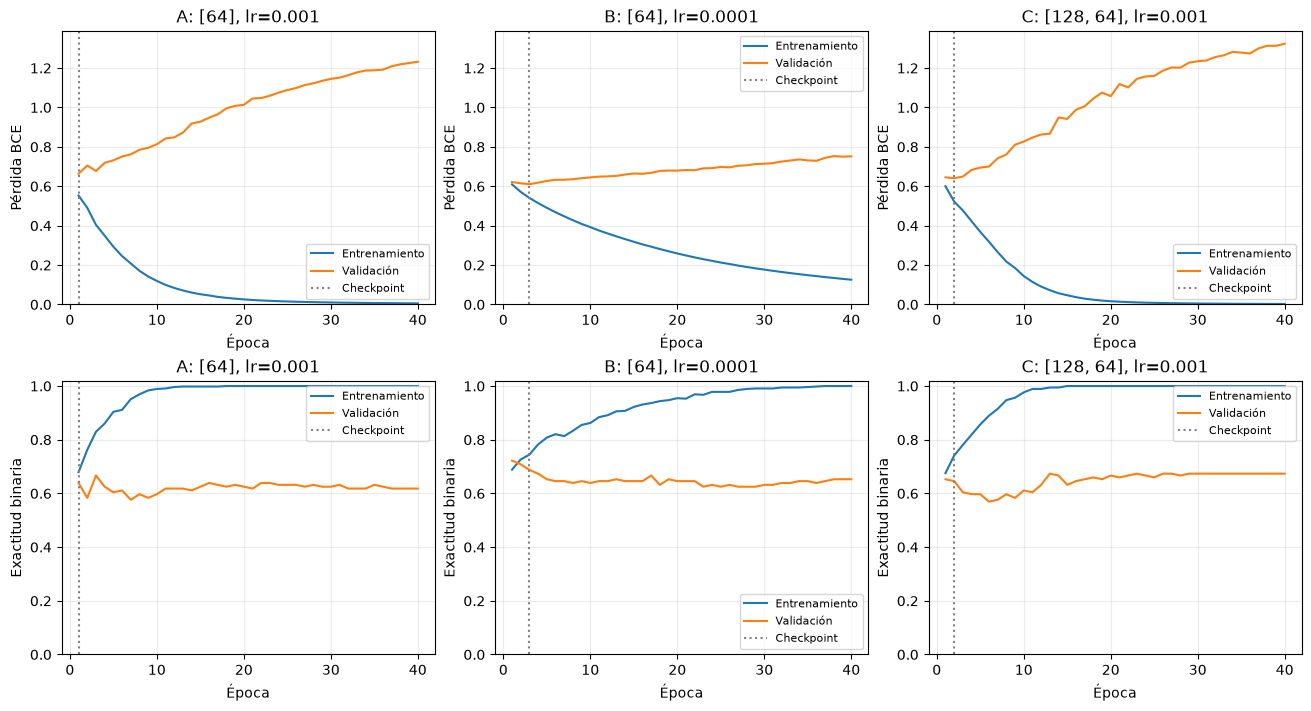

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7), constrained_layout=True)
loss_max = max(float(h[['train_loss', 'val_loss']].to_numpy().max()) for h in histories.values())
for col, config in enumerate(configs):
    name = config['experiment']
    h = histories[name]
    best_epoch = int(results.loc[results.experiment.eq(name), 'best_epoch'].iloc[0])
    for row, (train_col, val_col, ylabel) in enumerate([
        ('train_loss', 'val_loss', 'Pérdida BCE'),
        ('train_accuracy', 'val_accuracy', 'Exactitud binaria')]):
        ax = axes[row, col]
        ax.plot(h.epoch, h[train_col], label='Entrenamiento')
        ax.plot(h.epoch, h[val_col], label='Validación')
        ax.axvline(best_epoch, color='gray', linestyle=':', label='Checkpoint')
        ax.set(xlabel='Época', ylabel=ylabel, title=f'{name}: {config["hidden"]}, lr={config["lr"]:g}')
        ax.grid(alpha=0.25)
        if row == 1:
            ax.set_ylim(0, 1.02)
        else:
            ax.set_ylim(0, loss_max*1.05)
        ax.legend(fontsize=8)
fig.savefig(OUT / 'curvas_aprendizaje.png', dpi=180)
fig.savefig(OUT / 'curvas_aprendizaje.pdf')
plt.show()

## 6. Referencia trivial y comparación por hallazgo

Comparamos con probabilidades constantes iguales a la frecuencia de cada etiqueta en
entrenamiento. Esta referencia no aprende de las imágenes. Permite comprobar si la
red aporta algo más que predecir las categorías frecuentes. La configuración preferida
se elige por pérdida de validación, no por mirar repetidamente diferentes métricas.

In [8]:
constant_probs = np.repeat(y[train_idx].mean(axis=0)[None, :], len(val_idx), axis=0)
constant_loss = float(criterion(torch.logit(torch.from_numpy(constant_probs).clamp(1e-6, 1-1e-6)), y_val))
constant_metrics = metrics(y[val_idx], constant_probs)
print('Referencia de prevalencia:', {'val_loss': constant_loss, **constant_metrics})
best = min(summaries, key=lambda row: row['val_loss'])
best_probs = probabilities[best['experiment']]
per_class = []
for k, label in enumerate(labels):
    target = y[val_idx, k]
    pred = (best_probs[:, k] >= 0.5).astype(int)
    per_class.append({'hallazgo': label, 'positivos_val': int(target.sum()),
                      'negativos_val': int((1-target).sum()),
                      'auc': roc_auc_score(target, best_probs[:, k]) if len(np.unique(target)) == 2 else np.nan,
                      'f1': f1_score(target, pred, zero_division=0),
                      'sensibilidad': recall_score(target, pred, zero_division=0) if target.sum() else np.nan})
per_class = pd.DataFrame(per_class)
per_class.to_csv(OUT / 'metrics_per_class.csv', index=False)
display(per_class)
print('Configuración con menor pérdida de validación:', best['experiment'])

Referencia de prevalencia: {'val_loss': 0.5850012302398682, 'binary_accuracy': 0.7291666666666666, 'f1_micro': 0.38095238095238093, 'precision_micro': 0.5, 'recall_micro': 0.3076923076923077, 'auc_macro': 0.5, 'auc_classes': 10}


,hallazgo,positivos_val,negativos_val,auc,f1,sensibilidad
0,ACL,3,9,0.222222,0.000000,0.000
1,MCL,3,9,0.333333,0.000000,0.000
2,Medial Meniscus,5,7,0.371429,0.428571,0.600
3,Lateral Meniscus,4,8,0.218750,0.000000,0.000
4,Medial OA,4,8,0.343750,0.000000,0.000
5,Lateral OA,0,12,NaN,0.000000,NaN
6,PF OA,4,8,0.562500,0.000000,0.000
7,Effusion,8,4,0.562500,0.777778,0.875
8,Synovitis,4,8,0.562500,0.285714,0.250
9,Baker's,2,10,0.750000,0.000000,0.000


Configuración con menor pérdida de validación: B


## 7. Observaciones generadas a partir de los resultados

Las siguientes observaciones se calculan con las curvas de esta ejecución. No se
inventan métricas ni se atribuye significado clínico a una muestra tan pequeña.

In [9]:
observations = []
for row in summaries:
    h = histories[row['experiment']]
    final = h.iloc[-1]
    delta_train = float(h.iloc[0].train_loss-final.train_loss)
    delta_val = float(final.val_loss-row['val_loss'])
    observations.append(
        f"{row['experiment']}: capas {row['hidden']}, lr={row['lr']:g}, "
        f"{row['epochs']} épocas. La pérdida de entrenamiento disminuyó {delta_train:.4f} "
        f"desde la primera época. La menor pérdida de validación fue {row['val_loss']:.4f} "
        f"en la época {row['best_epoch']}; al final fue {final.val_loss:.4f} "
        f"(aumento respecto al mínimo: {delta_val:.4f}). "
        f"F1 micro del checkpoint: {row['f1_micro']:.4f}; "
        f"AUC macro: {row['auc_macro']:.4f} en {row['auc_classes']} hallazgos."
    )
for note in observations:
    print(note, '\n')
by_name = {row['experiment']: row for row in summaries}
comparison = [
    f"Al reducir la tasa de A a B, la pérdida mínima de validación cambió "
    f"de {by_name['A']['val_loss']:.4f} a {by_name['B']['val_loss']:.4f}. "
    "La menor tasa ralentiza el aprendizaje; el resultado debe leerse junto con las curvas.",
    f"C tiene {by_name['C']['parameters']:,} parámetros frente a "
    f"{by_name['A']['parameters']:,} de A. Su F1 micro cambió de "
    f"{by_name['A']['f1_micro']:.4f} a {by_name['C']['f1_micro']:.4f}; "
    "aumentar la capacidad no garantiza una mejora en todos los indicadores.",
    f"La configuración preferida por pérdida es {best['experiment']} "
    f"({best['val_loss']:.4f}). La referencia constante obtiene {constant_loss:.4f}. "
    + ("La red no supera esa referencia en pérdida de validación."
       if best['val_loss'] >= constant_loss else "La red mejora esa referencia en pérdida de validación."),
]
overfit = all(float(histories[r['experiment']].iloc[-1].val_loss) > r['val_loss']
              and float(histories[r['experiment']].iloc[-1].train_loss) < r['train_loss']
              for r in summaries)
if overfit:
    comparison.append('En los tres casos la pérdida de entrenamiento sigue bajando después '
                      'del checkpoint mientras la pérdida de validación termina más alta: '
                      'esto es evidencia de sobreajuste en esta partición.')
missing_auc = per_class.loc[per_class.auc.isna(), 'hallazgo'].tolist()
comparison.append('No se puede calcular AUC para: '+', '.join(missing_auc)+
                  '. La sensibilidad tampoco se define cuando no hay positivos.')
observations.extend(comparison)
for note in comparison:
    print(note, '\n')
summary = {'n_train': len(train_idx), 'n_val': len(val_idx), 'input_shape': list(images.shape[1:]),
           'experiments': summaries, 'preferred_by_val_loss': best['experiment'],
           'constant_baseline': {'val_loss': constant_loss, **constant_metrics},
           'observations': observations, 'versions': versions,
           'dataset_sha256': hashlib.sha256(path.read_bytes()).hexdigest()}
(OUT / 'summary.json').write_text(json.dumps(summary, indent=2, ensure_ascii=False), encoding='utf-8')
(OUT / 'observaciones.txt').write_text('\n\n'.join(observations), encoding='utf-8')
print('Resultados guardados en:', OUT)

A: capas [64], lr=0.001, 40 épocas. La pérdida de entrenamiento disminuyó 0.5473 desde la primera época. La menor pérdida de validación fue 0.6634 en la época 1; al final fue 1.2318 (aumento respecto al mínimo: 0.5684). F1 micro del checkpoint: 0.3810; AUC macro: 0.4613 en 10 hallazgos. 

B: capas [64], lr=0.0001, 40 épocas. La pérdida de entrenamiento disminuyó 0.4838 desde la primera época. La menor pérdida de validación fue 0.6104 en la época 3; al final fue 0.7518 (aumento respecto al mínimo: 0.1414). F1 micro del checkpoint: 0.3478; AUC macro: 0.4627 en 10 hallazgos. 

C: capas [128, 64], lr=0.001, 40 épocas. La pérdida de entrenamiento disminuyó 0.5977 desde la primera época. La menor pérdida de validación fue 0.6409 en la época 2; al final fue 1.3234 (aumento respecto al mínimo: 0.6825). F1 micro del checkpoint: 0.2609; AUC macro: 0.4169 en 10 hallazgos. 

Al reducir la tasa de A a B, la pérdida mínima de validación cambió de 0.6634 a 0.6104. La menor tasa ralentiza el aprendiza

- Son 58 estudios y una sola partición. No hay evaluación externa ni test independiente.
- Se usan cinco cortes por UID de una sola serie; pueden omitir las lesiones.
- Reducir a 32 × 32 elimina detalle y aplanar ignora relaciones espaciales entre píxeles.
- Las curvas y métricas muestran el comportamiento de este ejercicio, no eficacia clínica.
- La CNN deberá tener una preparación más formal, más datos y una evaluación independiente.
  Para comparar arquitecturas deberá reutilizarse una representación de entrada y partición
  compatibles; estos resultados por sí solos no prueban que una CNN sea superior.
